# Starter Code — Stereo Vision dengan 1 HP

**Petunjuk persiapan foto, alat, dan hal yang harus dicatat ada di `README.md`.** Notebook ini untuk menjalankan kode dan mengisi hasil. Jalankan **A → G** berurutan.

## A — Konfigurasi dan pemeriksaan file
Isi tiga nilai yang diukur. Untuk Colab, ubah `UPLOAD_ZIP = True`.

In [53]:
from pathlib import Path
import os, zipfile, csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

PATTERN_SIZE = (9, 6)        # sudut dalam; papan cetak 10 x 7 kotak
SQUARE_SIZE_MM = 25.0        # GANTI dengan ukuran satu kotak hasil penggaris
BASELINE_CM = 10.0           # GANTI dengan perpindahan pusat kamera L -> R
UPLOAD_ZIP = False          # True hanya di Google Colab
DATA_DIR = Path('.') if not UPLOAD_ZIP else Path('/content/PROJEK_COMVIS')

CAL_DIR = DATA_DIR/'calibration'
STEREO_DIR = DATA_DIR/'stereo'
OUT = DATA_DIR/'output'
OUT.mkdir(parents=True, exist_ok=True)
image_ext = {'.jpg','.jpeg','.png','.bmp'}
cal_files = sorted(p for p in CAL_DIR.iterdir() if p.suffix.lower() in image_ext) if CAL_DIR.exists() else []
L_PATH, R_PATH = STEREO_DIR/'kiri 50.jpeg', STEREO_DIR/'kanan 50.jpeg'
print('OpenCV:',cv2.__version__)
print('Foto kalibrasi:',len(cal_files),'| kiri:',L_PATH.exists(),'| kanan:',R_PATH.exists())
print('Kotak:',SQUARE_SIZE_MM,'mm | baseline:',BASELINE_CM,'cm')
if SQUARE_SIZE_MM <= 0 or BASELINE_CM <= 0: raise ValueError('Ukuran kotak dan baseline harus positif.')
if len(cal_files) < 10: raise RuntimeError('Sediakan setidaknya 10 foto kalibrasi (disarankan 15–25).')
if not L_PATH.exists() or not R_PATH.exists(): raise FileNotFoundError('Periksa stereo/kiri 100.jpeg dan stereo/kanan 100.jpeg')

OpenCV: 5.1.0
Foto kalibrasi: 21 | kiri: True | kanan: True
Kotak: 25.0 mm | baseline: 10.0 cm


## B — Deteksi sudut chessboard dan ukur jarak dalam piksel
Hasil `contoh jarak 2 sudut` adalah nilai **foto**, bukan focal length. Foto gagal otomatis dilewati.

Foto valid: 16 | Gagal: 5
Foto gagal: ['cal 13.jpeg', 'cal 16.jpeg', 'cal 2.jpeg', 'cal 3.jpeg', 'cal 4.jpeg']
Contoh jarak dua sudut dalam piksel: 84.12


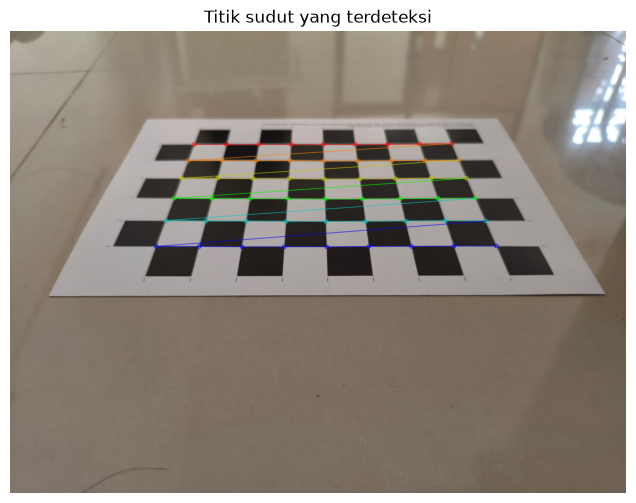

In [54]:
cols, rows = PATTERN_SIZE
obj = np.zeros((cols*rows,3),np.float32)
obj[:,:2] = np.mgrid[0:cols,0:rows].T.reshape(-1,2) * SQUARE_SIZE_MM
objpoints, imgpoints, ok_files, bad_files, spacings = [],[],[],[],[]
size_wh = None
preview = None
for path in cal_files:
    img = cv2.imread(str(path))
    if img is None: bad_files.append(path.name); continue
    gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    wh = (gray.shape[1],gray.shape[0])
    if size_wh is None: size_wh=wh
    if wh != size_wh:
        bad_files.append(path.name+' (resolusi berbeda)'); continue
    found,corners = cv2.findChessboardCornersSB(gray, PATTERN_SIZE)
    if not found: bad_files.append(path.name); continue
    corners = corners.astype(np.float32)
    objpoints.append(obj.copy()); imgpoints.append(corners)
    ok_files.append(path.name)
    spacings.append(float(np.linalg.norm(corners[1,0]-corners[0,0])))
    if preview is None:
        preview=img.copy()
        cv2.drawChessboardCorners(preview,PATTERN_SIZE,corners,True)
print('Foto valid:',len(ok_files),'| Gagal:',len(bad_files))
print('Foto gagal:',bad_files)
print('Contoh jarak dua sudut dalam piksel:', round(spacings[0],2) if spacings else None)
if preview is not None:
    plt.figure(figsize=(10,6));plt.imshow(cv2.cvtColor(preview,cv2.COLOR_BGR2RGB));plt.title('Titik sudut yang terdeteksi');plt.axis('off');plt.show()
    cv2.imwrite(str(OUT/'corners_preview.jpg'),preview)
if len(ok_files) < 10: raise RuntimeError('Titik sudut berhasil dideteksi pada <10 foto. Ulangi/ambil foto baru.')

## C — Kalibrasi kamera: hasil `fx`, `fy`, `cx`, `cy`
Periksa RMS dan simpan hasilnya. **Tidak ada angka focal length asumsi**.

In [55]:
rms,K,dist,rvecs,tvecs=cv2.calibrateCamera(objpoints,imgpoints,size_wh,None,None)
fx,fy,cx,cy = K[0,0],K[1,1],K[0,2],K[1,2]
print('Resolusi kalibrasi:',size_wh)
print('K =\n',K)
print(f'fx={fx:.2f} px | fy={fy:.2f} px | cx={cx:.2f} px | cy={cy:.2f} px')
print(f'RMS reprojection error={rms:.3f} px')
print('Distorsi:',dist.ravel())
np.savez(OUT/'calibration.npz',K=K,dist=dist,image_wh=size_wh,rms=rms,square_size_mm=SQUARE_SIZE_MM)
if not np.isfinite(rms) or rms > 2.0:
    print('PERHATIAN: RMS cukup besar. Periksa foto kalibrasi dan kesesuaian pola.')

Resolusi kalibrasi: (1600, 1200)
K =
 [[1.25908570e+03 0.00000000e+00 7.95960981e+02]
 [0.00000000e+00 1.25630623e+03 5.99457531e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
fx=1259.09 px | fy=1256.31 px | cx=795.96 px | cy=599.46 px
RMS reprojection error=0.531 px
Distorsi: [ 1.26570928e-01 -4.42464976e-01 -2.78403051e-03 -3.93386393e-04
  1.91510631e-01]


## D — Cek alignment pasangan foto
Matching fitur dilakukan pada seluruh gambar tanpa pemotongan atau ROI. Sel ini hanya memeriksa alignment; perhitungan tiap uji dilakukan terpisah di E?F.


Match global=419 | inlier=187 | median error epipolar=0.37 px


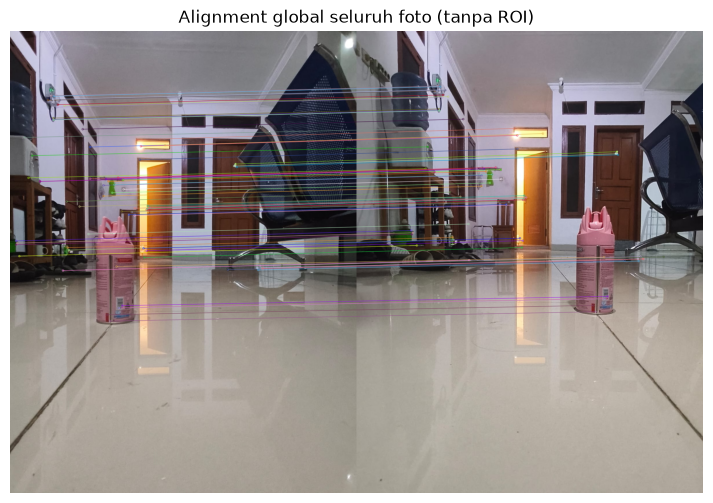

Alignment global lolos pemeriksaan awal.


In [56]:
left=cv2.imread(str(L_PATH));right=cv2.imread(str(R_PATH))
if left is None or right is None: raise ValueError('Gagal membaca foto stereo')
if left.shape!=right.shape:
    raise ValueError(f'Resolusi foto stereo berbeda: kiri={left.shape[1]}x{left.shape[0]}, kanan={right.shape[1]}x{right.shape[0]}')
stereo_wh=(left.shape[1],left.shape[0])

# Pemeriksaan alignment memakai fitur dari seluruh pasangan foto, tanpa ROI.
lg=cv2.cvtColor(left,cv2.COLOR_BGR2GRAY)
rg=cv2.cvtColor(right,cv2.COLOR_BGR2GRAY)
sift=cv2.SIFT_create(nfeatures=8000,contrastThreshold=0.015)
k1,desc1=sift.detectAndCompute(lg,None)
k2,desc2=sift.detectAndCompute(rg,None)
if desc1 is None or desc2 is None:
    raise RuntimeError('Foto stereo tidak memiliki cukup fitur global untuk diperiksa.')
pairs=cv2.BFMatcher().knnMatch(desc1,desc2,k=2)
good=[m for m,n in pairs if m.distance<0.75*n.distance]
if len(good)<30:
    raise RuntimeError(f'Match global hanya {len(good)}; gunakan pasangan foto yang lebih tajam/bertekstur.')
pL=np.float32([k1[m.queryIdx].pt for m in good])
pR=np.float32([k2[m.trainIdx].pt for m in good])
cv2.setRNGSeed(0)
F,mask=cv2.findFundamentalMat(pL,pR,cv2.FM_RANSAC,1.5,0.99)
if F is None or mask is None:
    raise RuntimeError('Estimasi alignment global gagal; periksa pasangan foto.')
inlier=mask.ravel().astype(bool)
if int(inlier.sum())<15:
    raise RuntimeError(f'Inlier global hanya {int(inlier.sum())}; pasangan foto belum cukup konsisten.')
xL=np.column_stack((pL[inlier],np.ones(int(inlier.sum()))))
xR=np.column_stack((pR[inlier],np.ones(int(inlier.sum()))))
FxL=(F@xL.T).T
FtxR=(F.T@xR.T).T
numerator=np.sum(xR*FxL,axis=1)**2
denominator=FxL[:,0]**2+FxL[:,1]**2+FtxR[:,0]**2+FtxR[:,1]**2
sampson=np.sqrt(numerator/np.maximum(denominator,1e-12))
median_sampson=float(np.median(sampson))
ALIGNMENT_OK=median_sampson<=2.0
inlier_matches=[m for m,keep in zip(good,inlier) if keep]
match_vis=cv2.drawMatches(left,k1,right,k2,inlier_matches[:80],None,flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
print(f'Match global={len(good)} | inlier={int(inlier.sum())} | median error epipolar={median_sampson:.2f} px')
plt.figure(figsize=(14,6));plt.imshow(cv2.cvtColor(match_vis,cv2.COLOR_BGR2RGB));plt.title('Alignment global seluruh foto (tanpa ROI)');plt.axis('off');plt.show()
if not ALIGNMENT_OK:
    raise RuntimeError('Alignment global belum cukup baik (median error epipolar > 2 px).')
if not cv2.imwrite(str(OUT/'matches.jpg'),match_vis):
    raise OSError('Gagal menyimpan visualisasi alignment global.')
print('Alignment global lolos pemeriksaan awal.')


## E — Siapkan perhitungan disparity
Fungsi di sel ini memproses setiap pasangan foto secara independen, mengestimasi rectification dari fitur global, dan menghitung disparity hanya pada ROI yang diberikan sel F. Koordinat ROI merujuk ke gambar kiri hasil undistort dan rectification.


In [57]:
def portrait_camera_model(calibration, image_shape):
    K_cal=calibration['K'].astype(np.float64)
    dist_cal=calibration['dist'].reshape(-1).astype(np.float64)
    calibration_wh=tuple(int(v) for v in calibration['image_wh'])
    image_wh=(image_shape[1],image_shape[0])
    if image_wh==calibration_wh:
        return K_cal,dist_cal
    if image_wh!=(calibration_wh[1],calibration_wh[0]):
        raise ValueError(f'Resolusi foto {image_wh} tidak cocok dengan kalibrasi {calibration_wh}.')
    width,height=calibration_wh
    K_portrait=np.array([
        [K_cal[1,1],0,K_cal[1,2]],
        [0,K_cal[0,0],width-1-K_cal[0,2]],
        [0,0,1]],dtype=np.float64)
    d=dist_cal
    dist_portrait=np.array([d[0],d[1],d[3],-d[2],d[4]],dtype=np.float64)
    return K_portrait,dist_portrait


def run_stereo_trial(test_id, distance_cm, roi_center_xy, roi_radius=12):
    if not ALIGNMENT_OK:
        raise RuntimeError('Jalankan dan pastikan alignment global di sel D lolos terlebih dahulu.')
    left_path=STEREO_DIR/f'kiri {distance_cm}.jpeg'
    right_path=STEREO_DIR/f'kanan {distance_cm}.jpeg'
    left=cv2.imread(str(left_path));right=cv2.imread(str(right_path))
    if left is None or right is None:
        raise FileNotFoundError(f'Foto untuk {test_id} ({distance_cm} cm) tidak ditemukan atau gagal dibaca.')
    if left.shape!=right.shape:
        raise ValueError(f'Resolusi kiri dan kanan berbeda pada {test_id}.')
    h,w=left.shape[:2]
    K,dist=portrait_camera_model(np.load(OUT/'calibration.npz'),left.shape)
    gray_left=cv2.cvtColor(left,cv2.COLOR_BGR2GRAY)
    gray_right=cv2.cvtColor(right,cv2.COLOR_BGR2GRAY)
    sift=cv2.SIFT_create(nfeatures=8000,contrastThreshold=0.015)
    kp_left,desc_left=sift.detectAndCompute(gray_left,None)
    kp_right,desc_right=sift.detectAndCompute(gray_right,None)
    if desc_left is None or desc_right is None:
        raise RuntimeError(f'Fitur global tidak cukup pada {test_id}.')
    pairs=cv2.BFMatcher().knnMatch(desc_left,desc_right,k=2)
    good=[m for m,n in pairs if m.distance<0.75*n.distance]
    if len(good)<40:
        raise RuntimeError(f'Match global hanya {len(good)} pada {test_id}.')
    points_left=np.float32([kp_left[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    points_right=np.float32([kp_right[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    points_left_u=cv2.undistortPoints(points_left,K,dist,P=K).reshape(-1,2)
    points_right_u=cv2.undistortPoints(points_right,K,dist,P=K).reshape(-1,2)
    cv2.setRNGSeed(0)
    E,essential_mask=cv2.findEssentialMat(
        points_left_u,points_right_u,K,method=cv2.USAC_MAGSAC,
        prob=0.999,threshold=1.0,maxIters=10000)
    if E is None or essential_mask is None:
        raise RuntimeError(f'Estimasi pose stereo gagal pada {test_id}.')
    pose_count,R,T,pose_mask=cv2.recoverPose(
        E,points_left_u,points_right_u,K,mask=essential_mask)
    if pose_count<40:
        raise RuntimeError(f'Inlier pose global hanya {pose_count} pada {test_id}.')
    T=T*(BASELINE_CM/100.0)
    R1,R2,P1,P2,Q,_,_=cv2.stereoRectify(
        K,dist,K,dist,(w,h),R,T,flags=cv2.CALIB_ZERO_DISPARITY,alpha=0)
    rect_left_map=cv2.initUndistortRectifyMap(K,dist,R1,P1[:,:3],(w,h),cv2.CV_32FC1)
    rect_right_map=cv2.initUndistortRectifyMap(K,dist,R2,P2[:,:3],(w,h),cv2.CV_32FC1)
    left_rect=cv2.remap(left,*rect_left_map,cv2.INTER_LINEAR)
    right_rect=cv2.remap(right,*rect_right_map,cv2.INTER_LINEAR)
    inliers=pose_mask.ravel().astype(bool)
    rect_points_left=cv2.undistortPoints(points_left,K,dist,R=R1,P=P1).reshape(-1,2)
    rect_points_right=cv2.undistortPoints(points_right,K,dist,R=R2,P=P2).reshape(-1,2)
    median_vertical=float(np.median(np.abs(rect_points_left[inliers,1]-rect_points_right[inliers,1])))
    if median_vertical>2.0:
        raise RuntimeError(f'Rectification {test_id} belum sejajar: median beda baris {median_vertical:.2f} px.')

    roi_x,roi_y=map(int,roi_center_xy)
    x0,x1=roi_x-roi_radius,roi_x+roi_radius+1
    y0,y1=roi_y-roi_radius,roi_y+roi_radius+1
    if x0<0 or y0<0 or x1>w or y1>h:
        raise ValueError(f'ROI {test_id} {(x0,y0,x1,y1)} berada di luar gambar {w}x{h}.')
    num_disparities=512
    expected_negative=float(P2[0,3])>0
    min_disparity=-num_disparities if expected_negative else 0
    search_margin=40
    if expected_negative:
        crop_x0=max(0,x0-search_margin)
        crop_x1=min(w,x1+num_disparities+search_margin)
    else:
        crop_x0=max(0,x0-num_disparities-search_margin)
        crop_x1=min(w,x1+search_margin)
    crop_y0=max(0,y0-search_margin)
    crop_y1=min(h,y1+search_margin)
    gray_left_rect=cv2.cvtColor(left_rect,cv2.COLOR_BGR2GRAY)
    gray_right_rect=cv2.cvtColor(right_rect,cv2.COLOR_BGR2GRAY)
    left_crop=np.ascontiguousarray(gray_left_rect[crop_y0:crop_y1,crop_x0:crop_x1])
    right_crop=np.ascontiguousarray(gray_right_rect[crop_y0:crop_y1,crop_x0:crop_x1])
    if left_crop.shape!=right_crop.shape or left_crop.shape[1]<=num_disparities:
        raise RuntimeError(f'Crop disparity {test_id} terlalu kecil untuk rentang {num_disparities} px.')
    sgbm=cv2.StereoSGBM_create(
        minDisparity=min_disparity,numDisparities=num_disparities,blockSize=5,
        P1=8*25,P2=32*25,uniquenessRatio=5,speckleWindowSize=0,
        speckleRange=2,disp12MaxDiff=1,mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
    crop_disparity=sgbm.compute(left_crop,right_crop).astype(np.float32)/16.0
    local_x0,local_x1=x0-crop_x0,x1-crop_x0
    local_y0,local_y1=y0-crop_y0,y1-crop_y0
    roi_disparity=crop_disparity[local_y0:local_y1,local_x0:local_x1]
    if expected_negative:
        valid=np.isfinite(roi_disparity)&(roi_disparity<=-0.5)&(roi_disparity>=min_disparity)
    else:
        valid=np.isfinite(roi_disparity)&(roi_disparity>=0.5)&(roi_disparity<num_disparities)
    valid_count=int(valid.sum())
    valid_percent=valid_count/valid.size*100
    if valid_count<10:
        raise RuntimeError(f'ROI {test_id} hanya memiliki {valid_count}/{valid.size} disparity valid.')
    disparity_median=float(np.median(roi_disparity[valid]))
    roi_depth=np.full(roi_disparity.shape,np.nan,dtype=np.float32)
    roi_depth[valid]=abs(float(P2[0,3]))/np.abs(roi_disparity[valid])
    depth_median=float(np.median(roi_depth[valid]))
    true_depth_m=distance_cm/100.0
    error_percent=abs(depth_median-true_depth_m)/true_depth_m*100
    record={
        'uji':test_id,'baseline_cm':BASELINE_CM,'square_size_mm':SQUARE_SIZE_MM,
        'fx_px':round(float(K[0,0]),3),'fy_px':round(float(K[1,1]),3),
        'rms_px':round(float(np.load(OUT/'calibration.npz')['rms']),3),
        'median_vertical_error_px':round(median_vertical,3),
        'disparity_roi_px':round(disparity_median,3),
        'depth_est_m':round(depth_median,4),'depth_meter_m':round(true_depth_m,4),
        'error_pct':round(error_percent,2)}
    disparity_map=np.full((h,w),np.nan,dtype=np.float32)
    depth_map=np.full((h,w),np.nan,dtype=np.float32)
    disparity_map[y0:y1,x0:x1]=np.where(valid,roi_disparity,np.nan)
    depth_map[y0:y1,x0:x1]=roi_depth
    tag=test_id.replace(' ','_')
    if not cv2.imwrite(str(OUT/f'left_rectified_{tag}.jpg'),left_rect):
        raise OSError(f'Gagal menyimpan gambar kiri rectified {test_id}.')
    roi_preview=left_rect.copy()
    cv2.rectangle(roi_preview,(x0,y0),(x1-1,y1-1),(0,0,255),3)
    cv2.drawMarker(roi_preview,(roi_x,roi_y),(0,255,255),cv2.MARKER_CROSS,15,2)
    if not cv2.imwrite(str(OUT/f'roi_{tag}.jpg'),roi_preview):
        raise OSError(f'Gagal menyimpan overlay ROI {test_id}.')
    np.save(OUT/f'disparity_px_{tag}.npy',disparity_map)
    np.save(OUT/f'depth_m_{tag}.npy',depth_map)
    return {
        'record':record,'left_rectified':left_rect,'roi_preview':roi_preview,
        'roi_disparity':np.where(valid,roi_disparity,np.nan),
        'roi_box':(x0,y0,x1,y1),'valid_count':valid_count,
        'valid_total':int(valid.size),'valid_percent':valid_percent}


## F — ROI depth per uji dan pemeriksaan hasil
Koordinat pusat ROI di bawah mengacu pada gambar kiri hasil undistort/rectification masing-masing pasangan (bukan gambar matching gabungan). Sel ini menampilkan kotak ROI dan disparity sebelum CSV disimpan di G.


uji_2: ROI=(388, 838, 413, 863) | disparity valid=624/625 (99.8%) | disparity median=-425.00 px | depth=0.336 m | meteran=0.500 m | error=32.88%


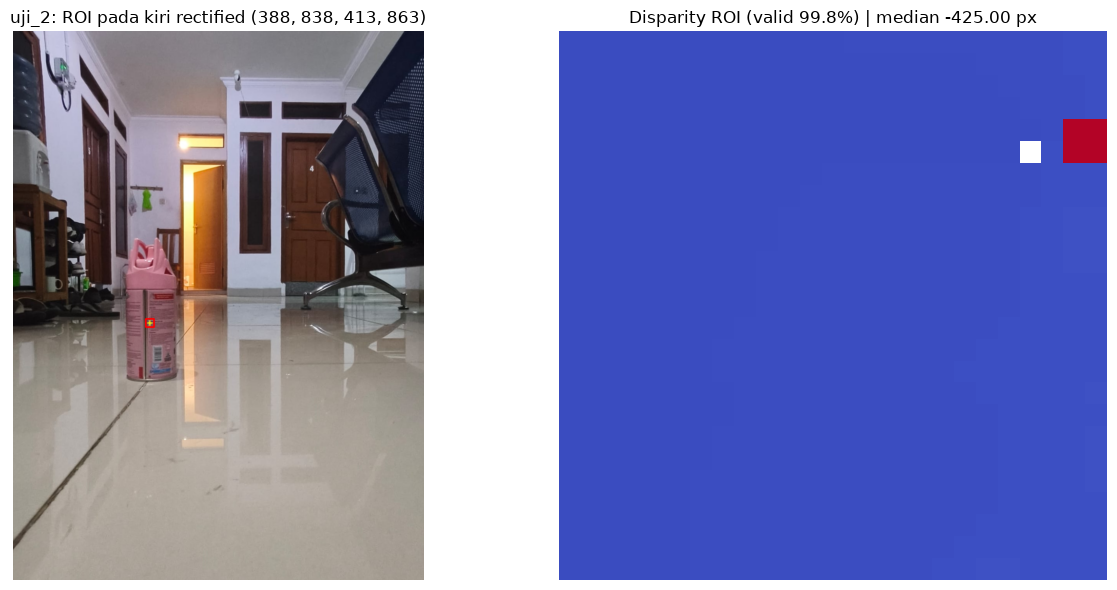

uji_3: ROI=(678, 828, 703, 853) | disparity valid=529/625 (84.6%) | disparity median=190.00 px | depth=0.702 m | meteran=1.500 m | error=53.23%


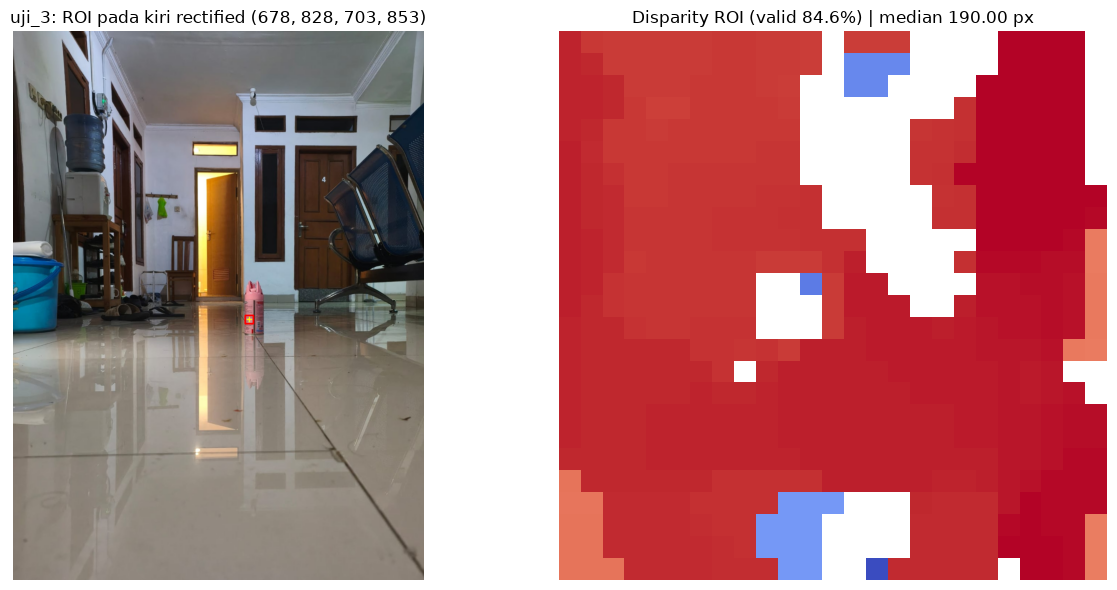

In [58]:
ROI_CONFIG={
    'uji_2':{'distance_cm':50,'center_xy':(400,850),'radius':12},
    'uji_3':{'distance_cm':150,'center_xy':(690,840),'radius':12}}
trial_results={}
for test_id,config in ROI_CONFIG.items():
    result=run_stereo_trial(
        test_id,config['distance_cm'],config['center_xy'],config['radius'])
    trial_results[test_id]=result
    record=result['record']
    print(
        f"{test_id}: ROI={result['roi_box']} | disparity valid="
        f"{result['valid_count']}/{result['valid_total']} "
        f"({result['valid_percent']:.1f}%) | disparity median="
        f"{record['disparity_roi_px']:.2f} px | depth="
        f"{record['depth_est_m']:.3f} m | meteran="
        f"{record['depth_meter_m']:.3f} m | error={record['error_pct']:.2f}%")
    fig,axes=plt.subplots(1,2,figsize=(13,6))
    axes[0].imshow(cv2.cvtColor(result['roi_preview'],cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"{test_id}: ROI pada kiri rectified {result['roi_box']}")
    axes[0].axis('off')
    axes[1].imshow(np.ma.masked_invalid(result['roi_disparity']),cmap='coolwarm')
    axes[1].set_title(
        f"Disparity ROI (valid {result['valid_percent']:.1f}%) | median {record['disparity_roi_px']:.2f} px")
    axes[1].axis('off')
    plt.tight_layout();plt.show()


## G — Simpan hasil setelah inspeksi ROI
Jalankan sel ini setelah kotak ROI pada F dipastikan hanya mencakup label botol. Sel ini memperbarui `uji_2` dan `uji_3` sekaligus, serta mempertahankan baris uji lain di CSV.


In [59]:
if not {'uji_2','uji_3'}.issubset(trial_results):
    raise RuntimeError('Jalankan dan periksa kedua hasil uji di sel F sebelum menyimpan CSV.')
csv_path=OUT/'hasil_pengukuran.csv'
new_records=[trial_results[test_id]['record'] for test_id in ('uji_2','uji_3')]
fieldnames=list(new_records[0])
rows=[]
if csv_path.exists():
    with csv_path.open(encoding='utf-8',newline='') as fh:
        rows=list(csv.DictReader(fh))
rows=[row for row in rows if row.get('uji') not in {'uji_2','uji_3'}]
rows.extend(new_records)
with csv_path.open('w',encoding='utf-8',newline='') as fh:
    writer=csv.DictWriter(fh,fieldnames=fieldnames)
    writer.writeheader();writer.writerows(rows)
print('Tersimpan:',csv_path)
for record in new_records:
    print(
        f"{record['uji']} | disparity ROI {record['disparity_roi_px']} px | "
        f"estimasi {record['depth_est_m']} m | meteran {record['depth_meter_m']} m | "
        f"error {record['error_pct']}%")


Tersimpan: output\hasil_pengukuran.csv
uji_2 | disparity ROI -425.0 px | estimasi 0.3356 m | meteran 0.5 m | error 32.88%
uji_3 | disparity ROI 190.0 px | estimasi 0.7016 m | meteran 1.5 m | error 53.23%


## Tugas analisis dan flowchart
**Ikuti format pengumpulan di README bagian 8.** Buat sendiri dua flowchart: (1) **A→B→C** dengan keputusan berhasil/gagal mendeteksi sudut; (2) **D→E→F→G** dengan keputusan alignment/ROI valid. Bandingkan minimal tiga jarak dan tulis penyebab error.

**Batasan:** proses ini menggunakan pendekatan translasi horizontal murni. Pemeriksaan alignment saja **tidak membuktikan** seluruh asumsi geometri terpenuhi; jangan melaporkan hasil sebagai jarak metrik terverifikasi tanpa perbandingan meteran.